# 02 — Alinhamento Temporal e Engenharia de Features

Junta as quatro fontes num dataset diário único e cria as features para a LSTM (`src/features/build_features.py`).

**Decisões de modelagem:**
- **Calendário de referência**: dias com indicador CEPEA arábica publicado (dias úteis BR). Pregões ausentes das outras fontes são preenchidos com o último valor conhecido (`ffill`) — nunca com valores futuros.
- **Alvo**: `cepea_arabica_brl_sc` — o preço físico em R$/saca que o produtor efetivamente recebe.
- **Partição cronológica estrita** (sem vazamento temporal). Como a bienalidade limita o ciclo de decisão do produtor a ~2 anos-safra, o teste cobre exatamente 2 safras (~720 dias corridos):
  - treino: 2005 → jun/2022 (~17 safras, inclui a geada de 2021)
  - validação: jul/2022 → jun/2024 (2 safras) — usada só para decisões de treino (early stopping, hiperparâmetros); se elas olhassem o teste, o backtest deixaria de ser cego
  - teste: jul/2024 → hoje (2 safras) — reservado exclusivamente ao backtest

**Grupos de features:**
| Grupo | Colunas | Motivação (síntese do TCC) |
|---|---|---|
| Conversão futuro→físico | `ice_arabica_brl_sc`, `base_fisico_futuro(_pct)` | risco de base regional |
| Retornos log | `ret_arabica_1d/21d`, `ret_robusta_1d`, `ret_ice_1d`, `ret_ptax_1d` | dinâmica de curto prazo |
| Médias móveis | `ma_1m/3m/1a/2a`, `preco_vs_ma_*` | tendência; base dos benchmarks |
| Volatilidade | `vol_21d` | regime de risco |
| Robusta | `spread_arabica_robusta` | substituição na demanda |
| Sazonalidade | `mes_sin/cos`, `bienalidade_alta`, `ano_safra` | ciclo bienal e safra |
| Macro | `ptax_venda`, `selic_meta` | câmbio e custo de oportunidade |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
plt.rcParams['figure.figsize'] = (12, 4)

from src.features.build_features import add_features, chronological_split, load_aligned

df = add_features(load_aligned())
df.to_csv(ROOT / 'data' / 'processed' / 'dataset_diario.csv')
print(df.shape)
df.tail(3)

(5169, 45)


,cepea_arabica_brl_sc,cepea_arabica_usd_sc,cepea_robusta_brl_sc,cepea_robusta_usd_sc,ice_arabica_cents_lb,usd_brl_yahoo,ptax_venda,selic_meta,cot_net_noncomm,cot_net_pct_oi,...,vol_21d,spread_arabica_robusta,cot_net_pct_oi_chg4w,indice_troca_urea,ret_urea_1a,ret_crude_1a,mes_sin,mes_cos,bienalidade_alta,ano_safra
date,,,,,,,,,,,,,,,,,,,,,
2026-08-27,1742.74,337.35,1021.90,197.81,341.899994,5.1474,5.1642,14.0,30365.0,0.185947,...,0.184546,1.705392,0.018797,1.163081,-0.234039,-0.127956,-0.866025,-0.5,1,2026
2026-08-28,1728.61,332.30,1027.55,197.53,345.850006,5.1611,5.2005,14.0,30472.0,0.190408,...,0.184170,1.682264,0.023741,1.180831,-0.234039,-0.127956,-0.866025,-0.5,1,2026
2026-08-31,1748.44,337.41,1022.13,197.25,343.899994,5.1912,5.1816,14.0,30472.0,0.190408,...,0.188669,1.710585,0.023741,1.163196,-0.234039,-0.127956,-0.866025,-0.5,1,2026


## 1. Físico × futuro convertido — o risco de base

O futuro ICE convertido para R$/saca (câmbio PTAX + fator 132,277 lb/saca) acompanha o físico, mas a diferença (base) varia — é exatamente o risco que o motor prescritivo precisa considerar.

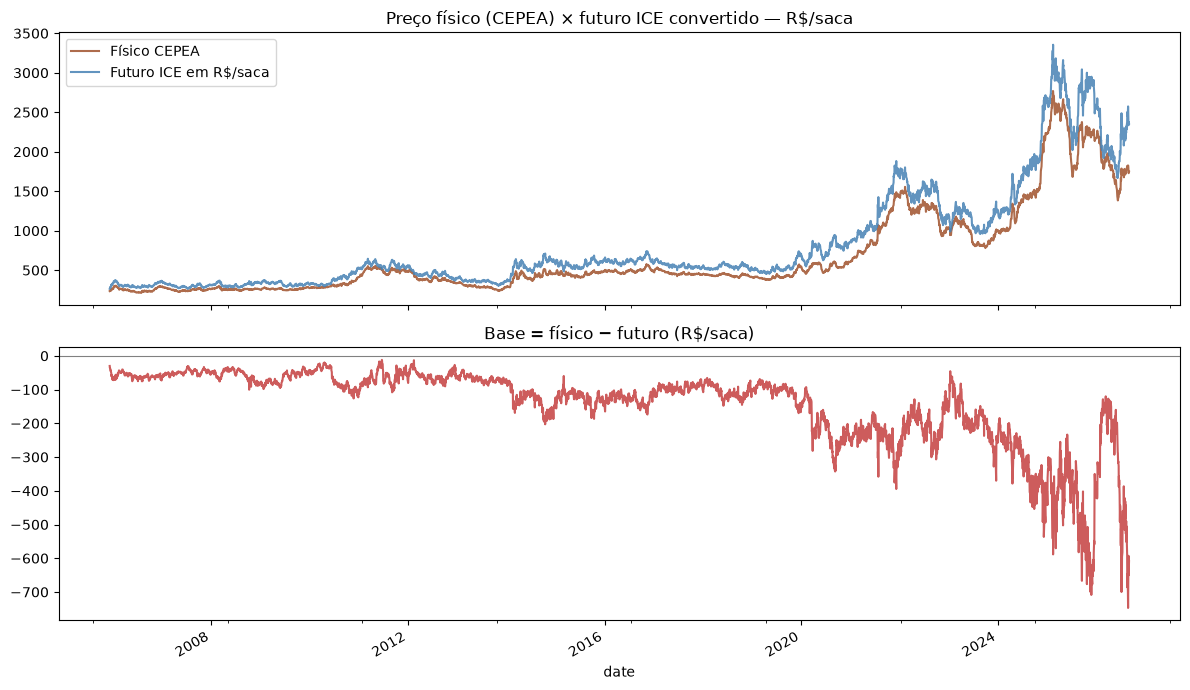

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
df[['cepea_arabica_brl_sc', 'ice_arabica_brl_sc']].plot(ax=axes[0], color=['sienna', 'steelblue'], alpha=0.85)
axes[0].set_title('Preço físico (CEPEA) × futuro ICE convertido — R$/saca')
axes[0].legend(['Físico CEPEA', 'Futuro ICE em R$/saca'])
df['base_fisico_futuro'].plot(ax=axes[1], color='indianred')
axes[1].axhline(0, color='gray', lw=0.8)
axes[1].set_title('Base = físico − futuro (R$/saca)')
plt.tight_layout()

## 2. Preço × médias móveis — matéria-prima dos benchmarks

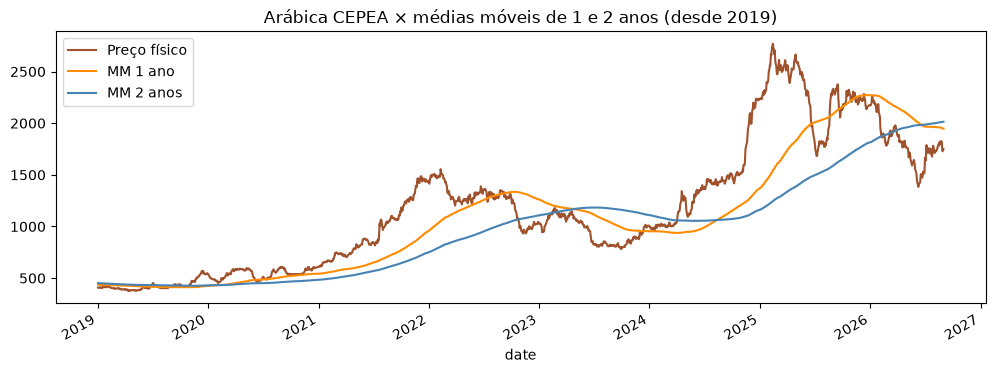

In [3]:
ax = df[['cepea_arabica_brl_sc', 'ma_1a', 'ma_2a']].loc['2019':].plot(
    color=['sienna', 'darkorange', 'steelblue'], title='Arábica CEPEA × médias móveis de 1 e 2 anos (desde 2019)')
ax.legend(['Preço físico', 'MM 1 ano', 'MM 2 anos'])

## 3. Volatilidade e spread arábica × robusta

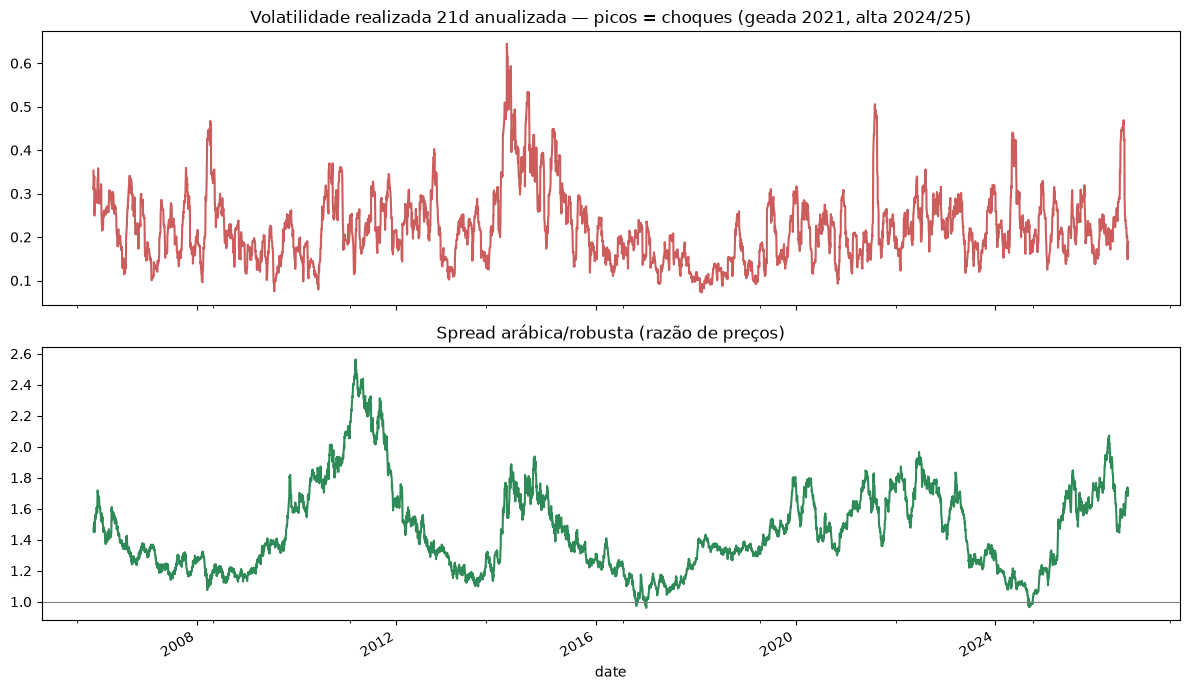

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
df['vol_21d'].plot(ax=axes[0], color='indianred', title='Volatilidade realizada 21d anualizada — picos = choques (geada 2021, alta 2024/25)')
df['spread_arabica_robusta'].plot(ax=axes[1], color='seagreen', title='Spread arábica/robusta (razão de preços)')
axes[1].axhline(1, color='gray', lw=0.8)
plt.tight_layout()

## 4. Partição cronológica treino / validação / teste

train : 2005-12-07 a 2022-06-30 | 4128 linhas
val   : 2022-07-01 a 2024-06-28 | 498 linhas
test  : 2024-07-01 a 2026-08-31 | 543 linhas


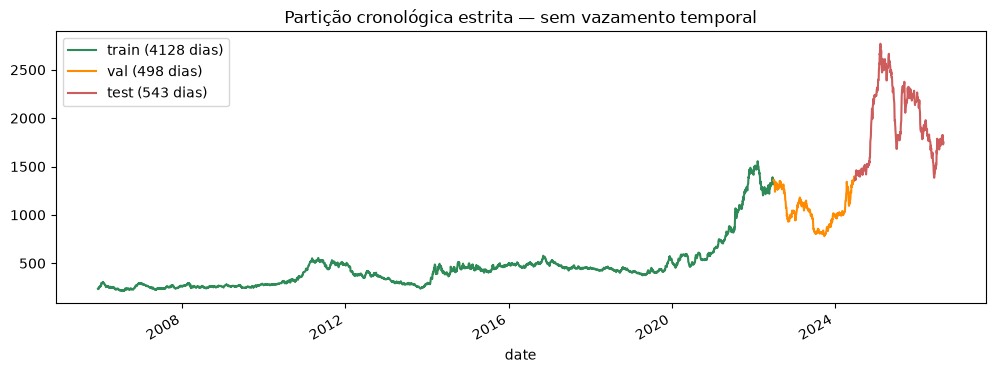

In [5]:
splits = chronological_split(df)
colors = {'train': 'seagreen', 'val': 'darkorange', 'test': 'indianred'}
fig, ax = plt.subplots()
for name, part in splits.items():
    part['cepea_arabica_brl_sc'].plot(ax=ax, color=colors[name], label=f'{name} ({len(part)} dias)')
ax.set_title('Partição cronológica estrita — sem vazamento temporal')
ax.legend()
for name, part in splits.items():
    print(f'{name:6s}: {part.index.min().date()} a {part.index.max().date()} | {len(part)} linhas')

## 5. Sanidade final

Sem NaNs, sem duplicatas, correlações das features com o alvo.

OK — sem NaNs, índice ordenado e sem duplicatas


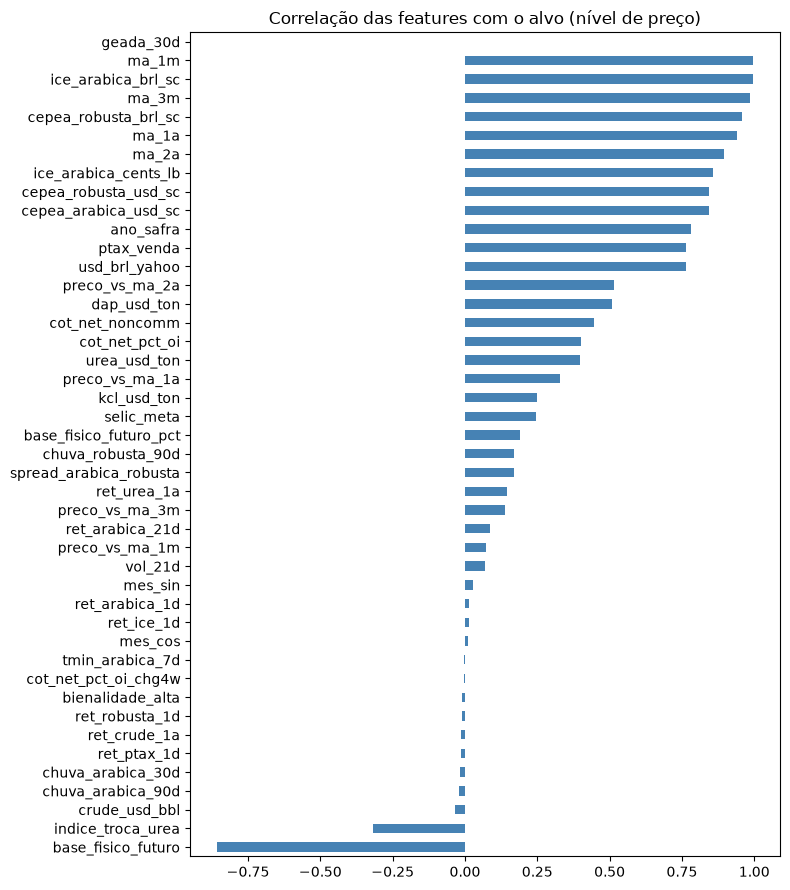

In [6]:
assert df.isna().sum().sum() == 0, 'NaNs no dataset!'
assert df.index.is_monotonic_increasing and not df.index.duplicated().any()
print('OK — sem NaNs, índice ordenado e sem duplicatas')

corr = df.corr(numeric_only=True)['cepea_arabica_brl_sc'].drop('cepea_arabica_brl_sc').sort_values()
corr.plot(kind='barh', figsize=(8, 9), color='steelblue', title='Correlação das features com o alvo (nível de preço)')
plt.tight_layout()

## 6. Preços em escala logarítmica

Em séries longas de preços, a escala log torna variações **percentuais** comparáveis ao longo do tempo: um salto de R\$100 para R\$200 tem o mesmo tamanho visual que de R\$1.000 para R\$2.000. Isso evita que a alta recente (2024/25) esmague visualmente os ciclos antigos e revela melhor a bienalidade e os choques históricos.

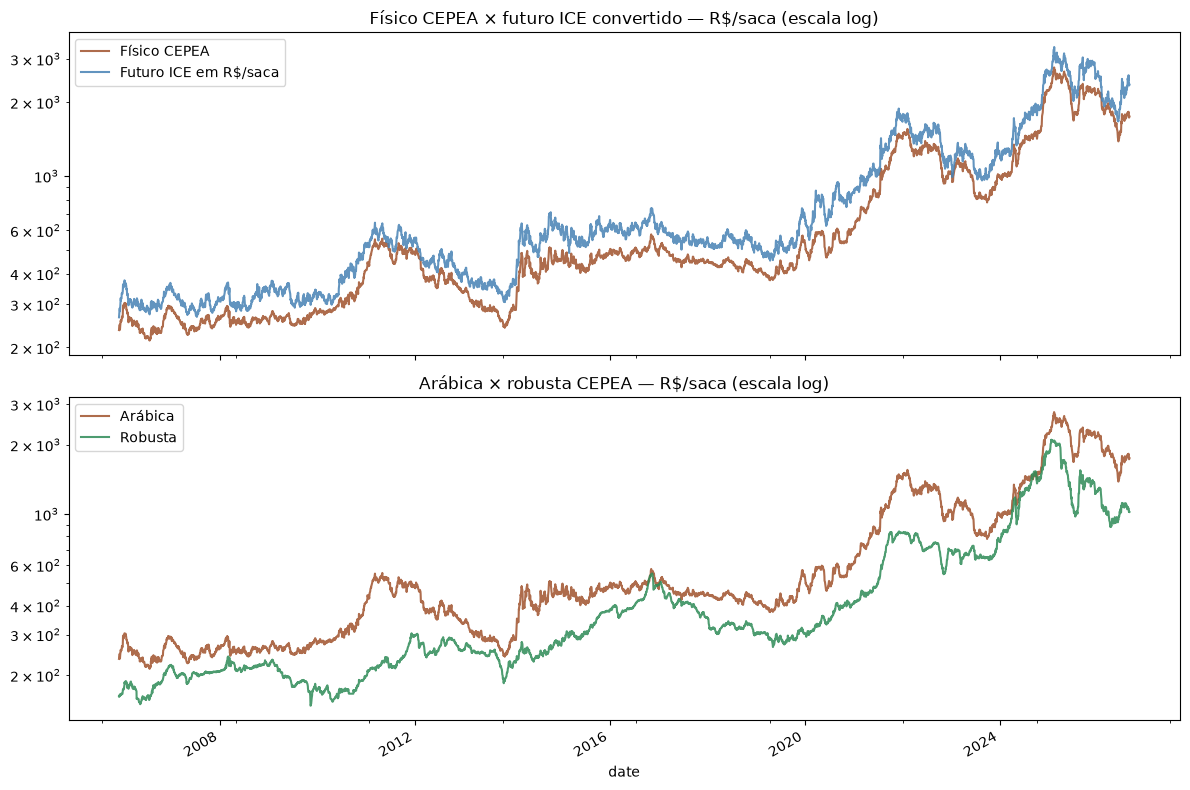

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
df[['cepea_arabica_brl_sc', 'ice_arabica_brl_sc']].plot(ax=axes[0], color=['sienna', 'steelblue'], alpha=0.85, logy=True)
axes[0].set_title('Físico CEPEA × futuro ICE convertido — R$/saca (escala log)')
axes[0].legend(['Físico CEPEA', 'Futuro ICE em R$/saca'])
df[['cepea_arabica_brl_sc', 'cepea_robusta_brl_sc']].plot(ax=axes[1], color=['sienna', 'seagreen'], alpha=0.85, logy=True)
axes[1].set_title('Arábica × robusta CEPEA — R$/saca (escala log)')
axes[1].legend(['Arábica', 'Robusta'])
plt.tight_layout()

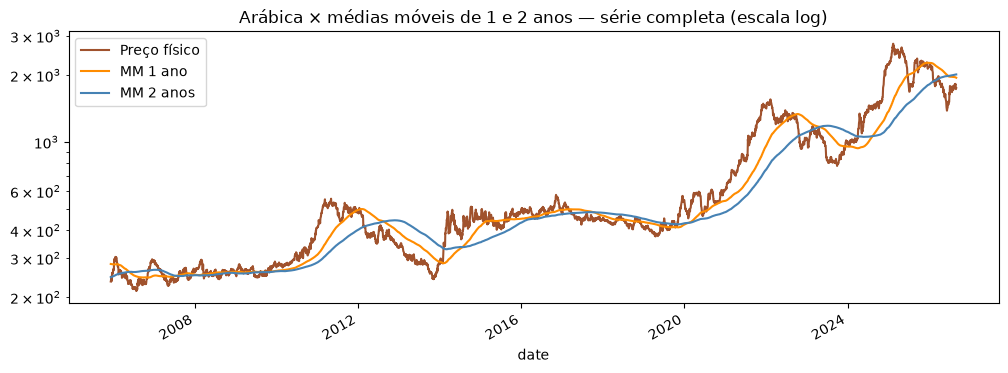

In [8]:
ax = df[['cepea_arabica_brl_sc', 'ma_1a', 'ma_2a']].plot(
    color=['sienna', 'darkorange', 'steelblue'], logy=True,
    title='Arábica × médias móveis de 1 e 2 anos — série completa (escala log)')
ax.legend(['Preço físico', 'MM 1 ano', 'MM 2 anos'])

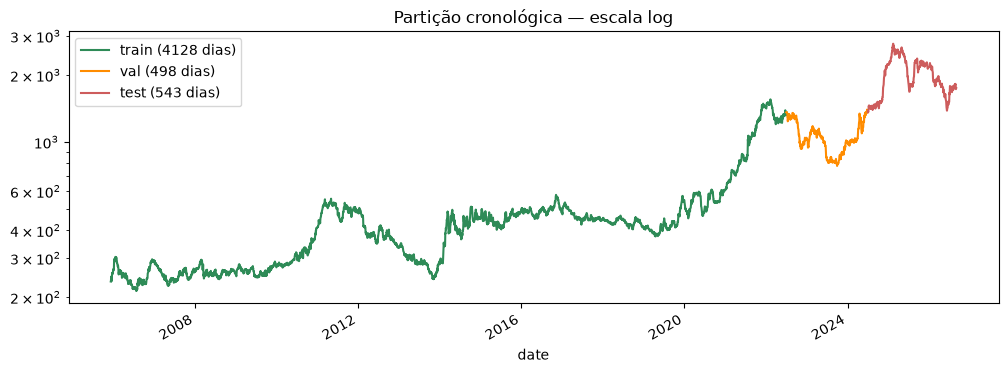

In [9]:
fig, ax = plt.subplots()
for name, part in splits.items():
    part['cepea_arabica_brl_sc'].plot(ax=ax, color=colors[name], label=f'{name} ({len(part)} dias)', logy=True)
ax.set_title('Partição cronológica — escala log')
ax.legend()